# Graphiques des metriques — modele BERT NER (run `reg`)

Lit le **log d'entrainement** (`slurm/logs/*.out`) et le **`test_metrics.json`**, puis trace toutes les courbes et graphiques :
loss, F1, precision, recall par epoque (train / validation / test), puis les metriques **par entite**.

Toutes les figures sont enregistrees en PNG dans `analysis/figures/` (pretes pour la these).

Requis : `pandas`, `matplotlib`. Lance : **Kernel -> Restart & Run All**.

In [1]:
import json
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Racine du projet = dossier contenant outputs/ et slurm/
ROOT = Path.cwd()
while not (ROOT / "outputs").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

LOG = sorted((ROOT / "slurm" / "logs").glob("*.out"))[-1]
METRICS = ROOT / "outputs" / "bio" / "bert" / "baseline" / "test_metrics.json"
FIG_DIR = ROOT / "analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Log      :", LOG.name)
print("Metrics  :", METRICS.name, "| existe:", METRICS.exists())
print("Figures ->", FIG_DIR)

Log      : bert_bio_baseline_reg-66204900.out
Metrics  : test_metrics.json | existe: True
Figures -> /Users/somaya/Documents/Phd/github_version/version_3/animalia-Github/deb_bert_version/deb_bert_version_reg_output/analysis/figures


### 1. Lecture du log -> tableau des metriques par epoque

In [2]:
EPOCH_RE = re.compile(r"^Epoch (\d+)/(\d+)")
LINE_RE = re.compile(r"^(Train|Val|Test)\s+-\s+Loss:\s*([\d.eE+-]+),\s*P:\s*([\d.]+),\s*R:\s*([\d.]+),\s*F1:\s*([\d.]+),\s*Acc:\s*([\d.]+)")
BEST_RE = re.compile(r"New best model saved \(F1: ([\d.]+)\)")

rows, cur, best_epochs = {}, None, []
for line in LOG.read_text().splitlines():
    m = EPOCH_RE.match(line)
    if m:
        cur = int(m.group(1))
        rows.setdefault(cur, {"epoch": cur})
        continue
    m = LINE_RE.match(line)
    if m and cur is not None:
        s = m.group(1).lower()
        rows[cur][f"{s}_loss"] = float(m.group(2))
        rows[cur][f"{s}_precision"] = float(m.group(3))
        rows[cur][f"{s}_recall"] = float(m.group(4))
        rows[cur][f"{s}_f1"] = float(m.group(5))
        rows[cur][f"{s}_acc"] = float(m.group(6))
        continue
    if BEST_RE.search(line) and cur is not None:
        best_epochs.append(cur)

df = pd.DataFrame(sorted(rows.values(), key=lambda r: r["epoch"]))
BEST_EPOCH = best_epochs[-1] if best_epochs else None
print(f"{len(df)} epoques parsees | meilleure epoque (val F1) : {BEST_EPOCH}")
df.to_csv(FIG_DIR / "metrics_per_epoch.csv", index=False)
df.head()

23 epoques parsees | meilleure epoque (val F1) : 13


,epoch,train_loss,train_precision,train_recall,train_f1,train_acc,val_loss,val_precision,val_recall,val_f1,val_acc,test_loss,test_precision,test_recall,test_f1,test_acc
0,1,1.0695,0.0807,0.3435,0.1307,0.8976,0.7480,0.5835,0.7570,0.6591,0.9803,0.7463,0.5828,0.7537,0.6573,0.9807
1,2,0.7181,0.7101,0.8184,0.7604,0.9883,0.7179,0.8298,0.9460,0.8841,0.9901,0.7154,0.8362,0.9487,0.8889,0.9908
2,3,0.7024,0.8549,0.9164,0.8846,0.9931,0.7071,0.8834,0.9595,0.9199,0.9928,0.7056,0.8838,0.9604,0.9205,0.9932
3,4,0.6984,0.8838,0.9331,0.9078,0.9941,0.7033,0.8986,0.9605,0.9285,0.9937,0.7014,0.9012,0.9649,0.9319,0.9941
4,5,0.6962,0.8952,0.9398,0.9170,0.9946,0.7011,0.8988,0.9618,0.9293,0.9936,0.6995,0.9016,0.9655,0.9324,0.9939


### 2. Courbes de loss (train / validation / test)

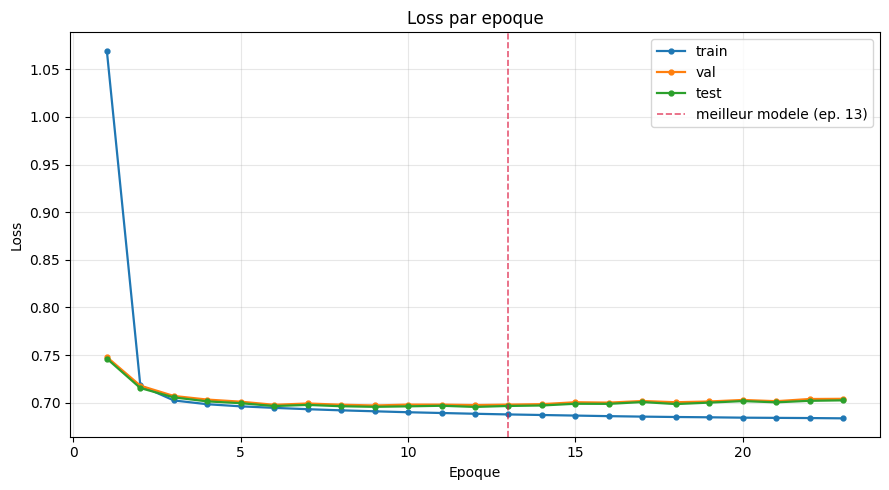

In [3]:
SPLITS = [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]

def curve(metric, ylabel, title, fname, ylim=None):
    fig, ax = plt.subplots(figsize=(9, 5))
    for s, color in SPLITS:
        col = f"{s}_{metric}"
        if col in df:
            ax.plot(df["epoch"], df[col], marker="o", ms=3.5, lw=1.6, color=color, label=s)
    if BEST_EPOCH:
        ax.axvline(BEST_EPOCH, ls="--", lw=1.2, color="crimson", alpha=0.7,
                   label=f"meilleur modele (ep. {BEST_EPOCH})")
    ax.set_xlabel("Epoque"); ax.set_ylabel(ylabel); ax.set_title(title)
    if ylim: ax.set_ylim(*ylim)
    ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=150); plt.show()

curve("loss", "Loss", "Loss par epoque", "01_loss.png")

### 3. Courbes de F1

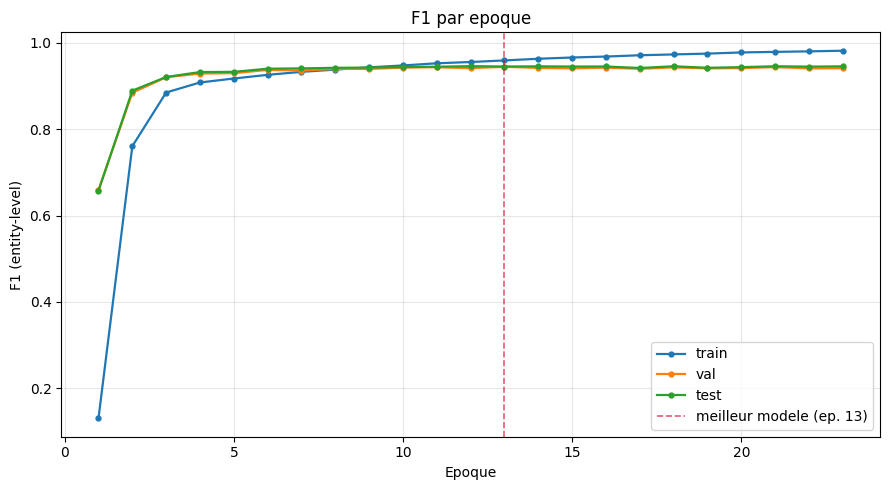

In [4]:
curve("f1", "F1 (entity-level)", "F1 par epoque", "02_f1.png")

### 4. Precision et Recall

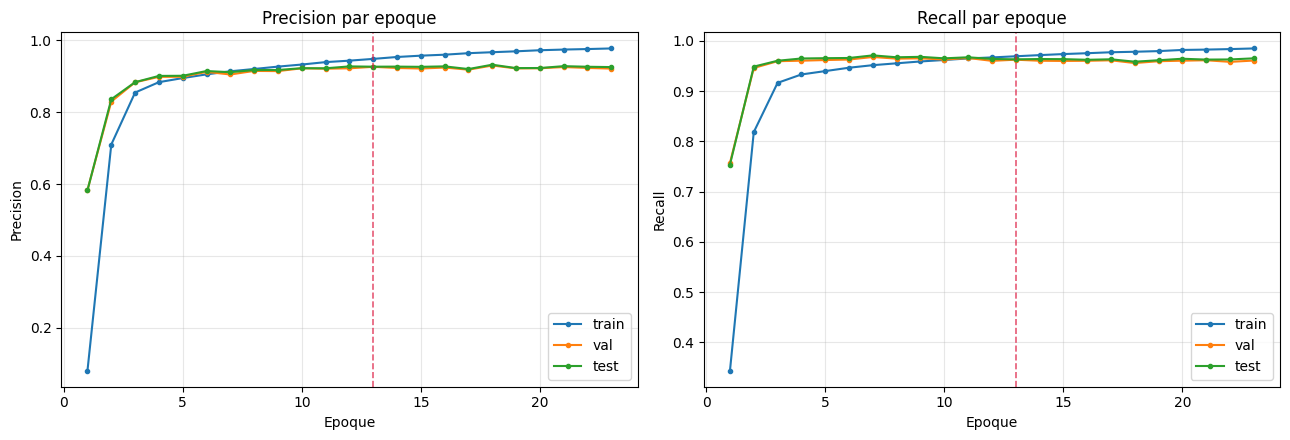

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, title in zip(axes, ["precision", "recall"], ["Precision", "Recall"]):
    for s, color in SPLITS:
        ax.plot(df["epoch"], df[f"{s}_{metric}"], marker="o", ms=3, lw=1.5, color=color, label=s)
    if BEST_EPOCH:
        ax.axvline(BEST_EPOCH, ls="--", lw=1.2, color="crimson", alpha=0.7)
    ax.set_xlabel("Epoque"); ax.set_ylabel(title); ax.set_title(f"{title} par epoque")
    ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "03_precision_recall.png", dpi=150); plt.show()

### 5. Vue d'ensemble (4 metriques)

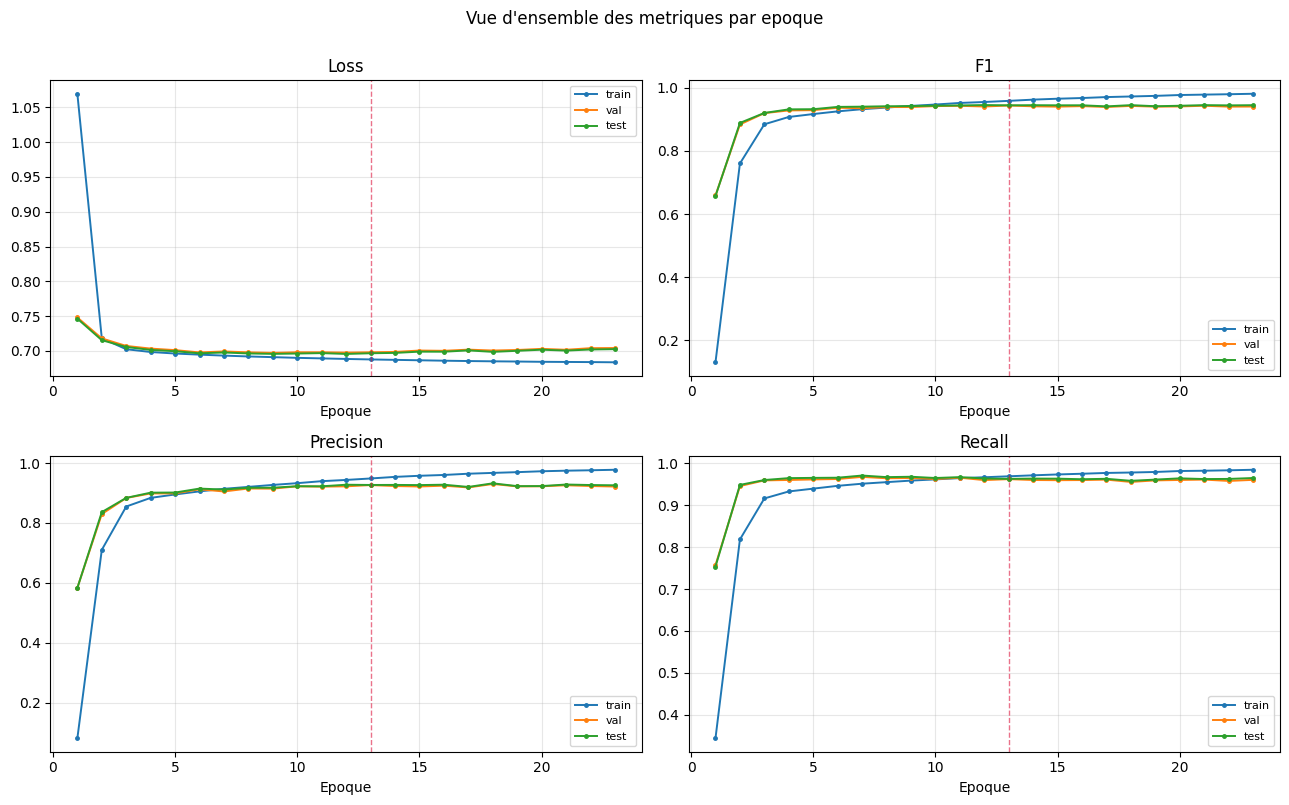

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (metric, title) in zip(axes.ravel(), [("loss", "Loss"), ("f1", "F1"), ("precision", "Precision"), ("recall", "Recall")]):
    for s, color in SPLITS:
        ax.plot(df["epoch"], df[f"{s}_{metric}"], marker="o", ms=2.5, lw=1.4, color=color, label=s)
    if BEST_EPOCH:
        ax.axvline(BEST_EPOCH, ls="--", lw=1, color="crimson", alpha=0.6)
    ax.set_title(title); ax.set_xlabel("Epoque"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle("Vue d'ensemble des metriques par epoque", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "04_overview.png", dpi=150); plt.show()

### 6. Metriques par entite (jeu de test)

In [7]:
m = json.loads(METRICS.read_text())
ents = sorted(k[len("test_f1_"):] for k in m if k.startswith("test_f1_"))
per = pd.DataFrame([{
    "entity": e,
    "precision": m[f"test_precision_{e}"],
    "recall": m[f"test_recall_{e}"],
    "f1": m[f"test_f1_{e}"],
    "support": int(m[f"test_support_{e}"]),
} for e in ents]).sort_values("f1", ascending=False).reset_index(drop=True)

per.to_csv(FIG_DIR / "per_entity_test.csv", index=False)
print(f"F1 global (test) : {m['test_f1']:.4f}   |   {len(per)} entites")
per

F1 global (test) : 0.9456   |   20 entites


,entity,precision,recall,f1,support
0,GSI,1.000000,1.000000,1.000000,77
1,T,0.978718,0.988726,0.983696,3814
2,Wwp,0.950581,0.990909,0.970326,330
3,JOi,0.951049,0.985507,0.967972,138
4,am,0.969083,0.965994,0.967536,941
5,Li,0.953593,0.960784,0.957175,663
6,Wwi,0.950485,0.961690,0.956055,1018
7,Wwx,0.936508,0.967213,0.951613,61
8,tg,0.930380,0.967105,0.948387,152
9,Lp,0.913313,0.959350,0.935765,615


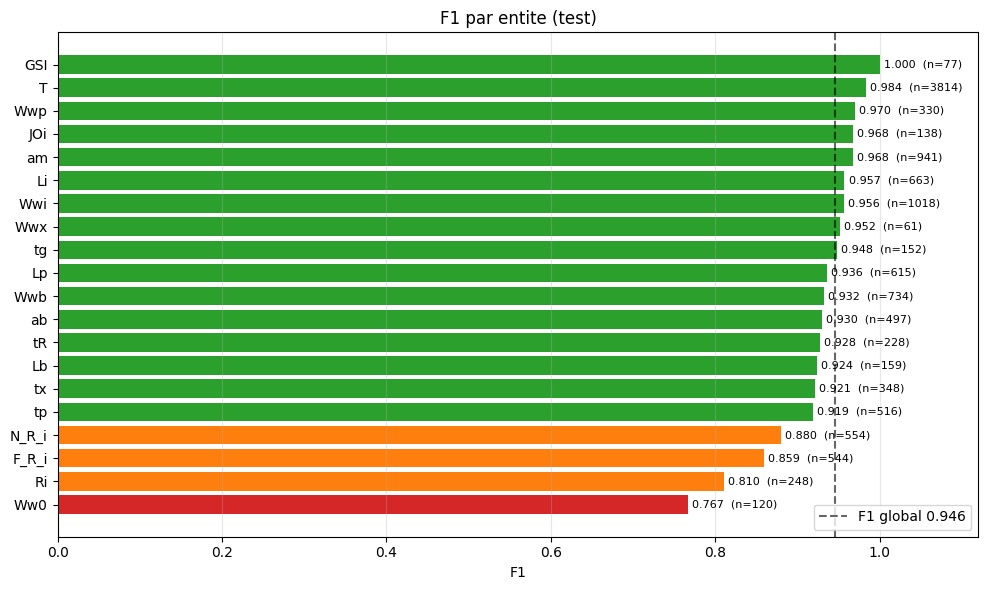

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["tab:green" if v >= 0.90 else "tab:orange" if v >= 0.80 else "tab:red" for v in per["f1"]]
ax.barh(per["entity"][::-1], per["f1"][::-1], color=colors[::-1])
ax.axvline(m["test_f1"], ls="--", color="black", alpha=0.6, label=f"F1 global {m['test_f1']:.3f}")
for y, (v, s) in enumerate(zip(per["f1"][::-1], per["support"][::-1])):
    ax.text(v + 0.005, y, f"{v:.3f}  (n={s})", va="center", fontsize=8)
ax.set_xlim(0, 1.12); ax.set_xlabel("F1"); ax.set_title("F1 par entite (test)")
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR / "05_f1_par_entite.png", dpi=150); plt.show()

### 7. Precision / Recall / F1 par entite (barres groupees)

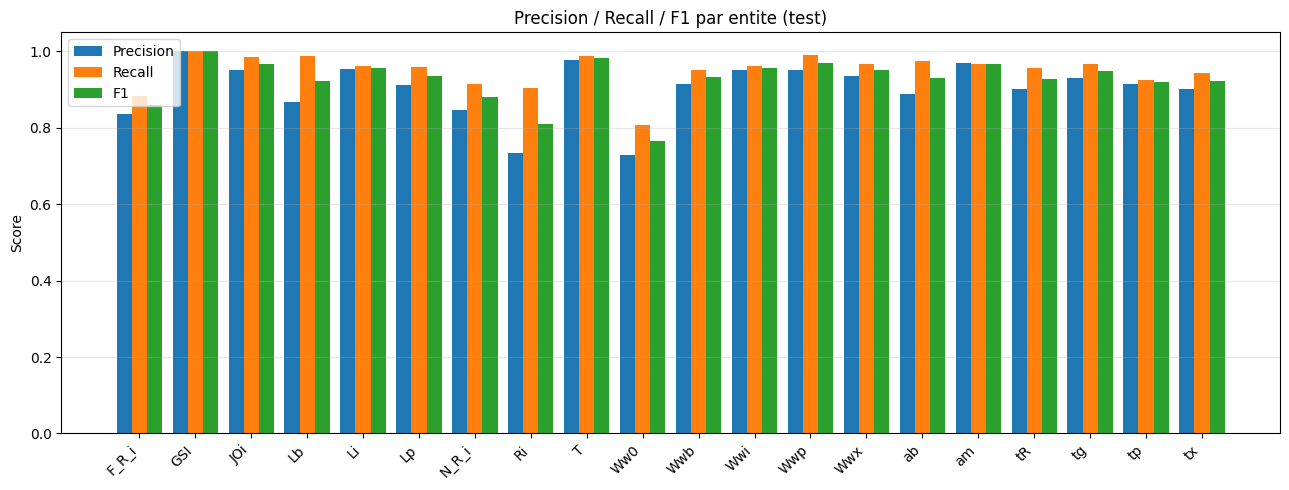

In [9]:
p = per.sort_values("entity")
x = range(len(p)); w = 0.27
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar([i - w for i in x], p["precision"], w, label="Precision", color="tab:blue")
ax.bar(list(x), p["recall"], w, label="Recall", color="tab:orange")
ax.bar([i + w for i in x], p["f1"], w, label="F1", color="tab:green")
ax.set_xticks(list(x)); ax.set_xticklabels(p["entity"], rotation=45, ha="right")
ax.set_ylim(0, 1.05); ax.set_ylabel("Score"); ax.set_title("Precision / Recall / F1 par entite (test)")
ax.legend(); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR / "06_prf_par_entite.png", dpi=150); plt.show()

### 8. F1 vs nombre d'exemples (pourquoi certaines classes sont faibles)

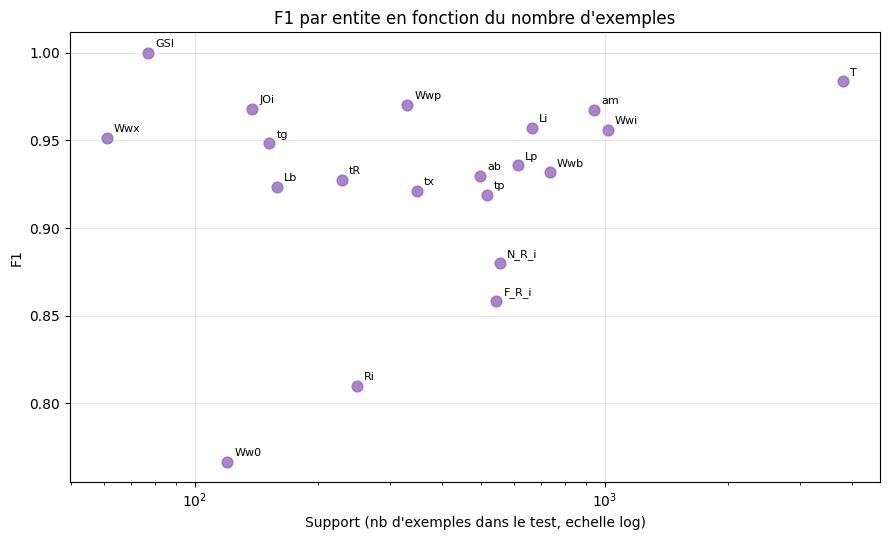

Figures enregistrees :
  - 01_loss.png
  - 02_f1.png
  - 03_precision_recall.png
  - 04_overview.png
  - 05_f1_par_entite.png
  - 06_prf_par_entite.png
  - 07_f1_vs_support.png


In [10]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(per["support"], per["f1"], s=60, color="tab:purple", alpha=0.8)
for _, r in per.iterrows():
    ax.annotate(r["entity"], (r["support"], r["f1"]), textcoords="offset points",
                xytext=(5, 4), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("Support (nb d'exemples dans le test, echelle log)")
ax.set_ylabel("F1"); ax.set_title("F1 par entite en fonction du nombre d'exemples")
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR / "07_f1_vs_support.png", dpi=150); plt.show()

print("Figures enregistrees :")
for f in sorted(FIG_DIR.glob("*.png")):
    print("  -", f.name)